# U2 - Integrante 1 - Pipeline en tiempo real: Monto operado (`quote_qty`)

**Proyecto Sello · BTC/USDT (Binance) → Kafka → Spark Structured Streaming → Prometheus/Grafana**

**Pregunta de negocio de mi dimensión:** ¿Cuánto volumen en USDT se operará en el próximo intervalo, y qué tan bien estima el modelo U1 el monto de cada operación en vivo?

- **Modelo U1 desplegado en vivo:** LinearRegression sobre `quote_qty` (regresión).
- **Serie de tiempo (S10):** predecir `volumen_usdt` de la barra siguiente.
- `quote_qty = price × qty`: el error en vivo del modelo U1 confirma además la **consistencia del dato** que llega por el puente.

## Qué cubre este notebook (sesiones S6 → S11 y criterios de S12)

| Sección | Sesión | Evidencia que produce |
|---|---|---|
| 1 | S6 / S7 | Contrato del evento, topic verificado, ritmo de ingesta, validación de esquema y de rango |
| 2 | S8 | Ventana fija y deslizante con *watermarking*, dato tardío descartado, deduplicación, comparación de *triggers*, persistencia Parquet con *checkpoint* |
| 3 | S9 | `lastProgress`, métricas de Prometheus, latencia por minuto, alertas con umbrales medidos, costos de escalado |
| 4 | S10 | Barras históricas, baseline de persistencia, 2 modelos MLlib, `PipelineModel` guardado y recargado |
| 5 | S11 | KPIs en Pushgateway, inferencia en vivo (serie + modelo U1), error medido en producción, consultas PromQL |
| 6 | S12 | Checklist de criterios de aceptación y `resumen_u2.json` |

**Arquitectura medalla:** Bronze = topic Kafka · Silver = `stream/eventos_obs` (eventos validados con observabilidad) · Gold = `gold_barras`, KPIs en Pushgateway y `stream/predicciones_ts`.

**Salidas de este notebook:** `artifacts/integrante1/` (modelo de serie de tiempo, métricas, Parquet de streaming, checkpoints y `resumen_u2.json`). Los artefactos de U1 se leen desde la raíz de `artifacts/`.

> **Requisitos antes de ejecutar:** `docker compose up -d` con `kafka`, `bridge-binance`, `prometheus`, `pushgateway`, `kafka-exporter` y `grafana` activos, y los notebooks U1 ya ejecutados (necesito `silver_integrante1` y `modelo_ganador_integrante1`).
> **Tiempo aproximado:** 12–15 min. Variables útiles: `LIVE_SECONDS` (duración de la sección 5), `BAR_SECONDS`, `WATERMARK`, `STARTING_OFFSETS`.

## 0. Sesión Spark y parámetros

In [1]:
import os, json, time, glob, shutil, threading, uuid, urllib.request, urllib.parse
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyspark

from pyspark.sql import SparkSession, functions as F, Window
from pyspark.sql.types import StructType, StructField, LongType, DoubleType, BooleanType, StringType
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.functions import vector_to_array
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

# ---------------- Identidad y dimension ----------------
INTEGRANTE  = 1
DIMENSION   = "monto_usdt"            # etiqueta usada en las metricas de Prometheus
TARGET_COL  = "volumen_usdt"         # variable de la serie de tiempo (S10)

# ---------------- Rutas (U1 en la raiz de artifacts; U2 en su carpeta) ----------------
WORK      = os.getenv("WORK_DIR", "/home/jovyan/work")
ARTIFACTS = os.getenv("ARTIFACTS_DIR", f"{WORK}/artifacts")      # salidas de U1 (silver, modelos ganadores)
OUT       = f"{ARTIFACTS}/integrante{INTEGRANTE}"                  # salidas de ESTE notebook
CKPT      = f"{OUT}/checkpoints"
RUN_ID    = datetime.now().strftime("%m%d%H%M%S")
os.makedirs(OUT, exist_ok=True)
if os.getenv("RESET_OUTPUTS", "1") == "1":                         # evidencia limpia en cada corrida
    for d in ("stream", "checkpoints"):
        shutil.rmtree(f"{OUT}/{d}", ignore_errors=True)
os.makedirs(CKPT, exist_ok=True)

# ---------------- Infraestructura (nombres del compose.yml) ----------------
KAFKA_BOOTSTRAP = os.getenv("KAFKA_BOOTSTRAP_SERVERS", "kafka:9092")
TOPIC           = os.getenv("KAFKA_TOPIC", "binance-btc-trades")
PUSHGATEWAY     = os.getenv("PUSHGATEWAY_URL", "http://pushgateway:9091")
PROMETHEUS      = os.getenv("PROMETHEUS_URL", "http://prometheus:9090")
STREAM_SOURCE   = os.getenv("STREAM_SOURCE", "kafka")             # "files": solo para pruebas sin Kafka
START_OFFSETS   = os.getenv("STARTING_OFFSETS", "latest")
TEST_DIR        = f"{OUT}/_test_stream"

# ---------------- Parametros del pipeline ----------------
BAR_SECONDS    = int(os.getenv("BAR_SECONDS", "10"))
BAR_WIDTH      = f"{BAR_SECONDS} seconds"
WATERMARK      = os.getenv("WATERMARK", "5 seconds")
LIVE_SECONDS   = int(os.getenv("LIVE_SECONDS", "150"))
WAIT_SCALE     = float(os.getenv("WAIT_SCALE", "1.0"))            # < 1.0 acorta las esperas (solo pruebas)
UMBRAL_BALLENA = 50000.0
RANGO_PRECIO   = (10000.0, 300000.0)                              # mismos limites que consumer_crypto.py
RANGO_QTY      = (0.000001, 500.0)
SEED           = 42
FEATS = ["n_trades", "volumen_btc", "volumen_usdt", "qty_media", "qty_max", "n_ballenas",
         "vol_ballenas_usdt", "pct_buyer_maker", "rango_rel", "retorno"]   # sin nivel de precio (evita deriva)

RESUMEN = {"integrante": INTEGRANTE, "dimension": DIMENSION, "target_serie": TARGET_COL,
           "bar_seconds": BAR_SECONDS, "watermark": WATERMARK, "run_id": RUN_ID}

builder = (SparkSession.builder
           .appName(f"U2-Integrante{INTEGRANTE}-{DIMENSION}")
           .master("local[*]")
           .config("spark.ui.port", "4040")
           .config("spark.sql.shuffle.partitions", "4")
           .config("spark.driver.memory", os.getenv("SPARK_DRIVER_MEMORY", "4g"))
           .config("spark.sql.session.timeZone", "UTC")
           .config("spark.sql.streaming.forceDeleteTempCheckpointLocation", "true"))
if STREAM_SOURCE == "kafka":   # conector Kafka alineado con la version de pyspark instalada
    builder = builder.config("spark.jars.packages", f"org.apache.spark:spark-sql-kafka-0-10_2.12:{pyspark.__version__}")
spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("WARN")
print(f"Spark {spark.version} | fuente: {STREAM_SOURCE} | topic: {TOPIC} | salidas U2: {OUT}")

Spark 3.5.0 | fuente: kafka | topic: binance-btc-trades | salidas U2: /home/jovyan/work/artifacts/integrante1


### Funciones comunes
Conexión a Kafka, contrato del evento, campos de observabilidad, barras de tiempo (misma función para histórico y vivo), Pushgateway y PromQL.

In [2]:
TEST_TOPIC     = f"u2-test-i{INTEGRANTE}-{RUN_ID}"       # tardio / watermark
TEST_TOPIC_DUP = f"u2-testdup-i{INTEGRANTE}-{RUN_ID}"    # duplicados
TEST_TOPIC_VAL = f"u2-testval-i{INTEGRANTE}-{RUN_ID}"    # validacion esquema / rango

def esperar(seg, msg=None):
    s = seg * WAIT_SCALE
    if msg:
        print(f"... {msg} ({s:.0f}s)")
    time.sleep(s)

def ultimo(q):
    return q.lastProgress or {}

# ---------------- Publicacion / lectura (Kafka o archivos) ----------------
_producer = None
def publicar(topic, evento, key="BTCUSDT"):
    """Publica un evento JSON (str = mensaje crudo, util para probar mensajes malformados)."""
    global _producer
    valor = evento if isinstance(evento, str) else json.dumps(evento)
    if STREAM_SOURCE == "kafka":
        from kafka import KafkaProducer
        if _producer is None:
            _producer = KafkaProducer(bootstrap_servers=KAFKA_BOOTSTRAP)
        _producer.send(topic, key=key.encode(), value=valor.encode()).get(timeout=15)
        _producer.flush()
    else:
        d = f"{TEST_DIR}/{topic}"; os.makedirs(d, exist_ok=True)
        tmp = f"{d}/.tmp_{uuid.uuid4().hex}"
        with open(tmp, "w") as f:
            f.write(valor + "\n")
        os.rename(tmp, f"{d}/ev_{time.time_ns()}.json")

def evento_test(trade_id, ts_ms, price=93000.0, qty=0.01, maker=False):
    return {"tipoEvento": "crypto.trade", "tradeId": trade_id, "symbol": "BTCUSDT", "price": price,
            "quantity": qty, "quoteQuantity": round(price * qty, 8), "isBuyerMaker": maker,
            "origen": f"test-integrante{INTEGRANTE}", "timestamp": ts_ms}

def consumir_test(topic, timeout_s=8):
    """Consume (grupo propio, desde el inicio) los mensajes de un topic de prueba."""
    out = []
    if STREAM_SOURCE == "kafka":
        from kafka import KafkaConsumer
        c = KafkaConsumer(topic, bootstrap_servers=KAFKA_BOOTSTRAP, group_id=f"u2-i{INTEGRANTE}-check-{uuid.uuid4().hex[:6]}",
                          auto_offset_reset="earliest", consumer_timeout_ms=int(timeout_s * 1000))
        for m in c:
            out.append((m.partition, m.offset, m.value.decode("utf-8", errors="replace")))
        c.close()
    else:
        for i, p in enumerate(sorted(glob.glob(f"{TEST_DIR}/{topic}/ev_*"))):
            out.append((0, i, open(p).read().strip()))
    return out

def leer_stream(topic=None, offsets=None):
    """Stream crudo: key, value, topic, partition, offset, kafka_ts."""
    topic = topic or TOPIC
    if STREAM_SOURCE == "kafka":
        return (spark.readStream.format("kafka")
                .option("kafka.bootstrap.servers", KAFKA_BOOTSTRAP)
                .option("subscribe", topic)
                .option("startingOffsets", offsets or START_OFFSETS)
                .option("failOnDataLoss", "false")
                .load()
                .select(F.col("key").cast("string").alias("key"), F.col("value").cast("string").alias("value"),
                        "topic", "partition", "offset", F.col("timestamp").alias("kafka_ts")))
    d = f"{TEST_DIR}/{topic}"; os.makedirs(d, exist_ok=True)
    return (spark.readStream.format("text").load(d)
            .select(F.lit(None).cast("string").alias("key"), "value", F.lit(topic).alias("topic"),
                    F.lit(0).alias("partition"), F.lit(0).cast("long").alias("offset"),
                    F.current_timestamp().alias("kafka_ts")))

def tasa_topic(topic, seg=5):
    """(particiones, offset_total, eventos_por_segundo) del topic."""
    if STREAM_SOURCE == "kafka":
        from kafka import KafkaConsumer, TopicPartition
        c = KafkaConsumer(bootstrap_servers=KAFKA_BOOTSTRAP)
        parts = sorted(c.partitions_for_topic(topic) or [])
        tps = [TopicPartition(topic, p) for p in parts]
        f1 = sum(c.end_offsets(tps).values()); time.sleep(seg)
        f2 = sum(c.end_offsets(tps).values()); c.close()
        return len(parts), f2, (f2 - f1) / seg
    n = lambda: sum(len(open(p).read().splitlines()) for p in glob.glob(f"{TEST_DIR}/{topic}/ev_*"))
    n1 = n(); time.sleep(seg); n2 = n()
    return 1, n2, (n2 - n1) / seg

# ---------------- Contrato del evento (producido por bridge_binance_kafka.py) ----------------
schema_evento = StructType([
    StructField("tipoEvento", StringType()), StructField("tradeId", LongType()),
    StructField("symbol", StringType()),     StructField("price", DoubleType()),
    StructField("quantity", DoubleType()),   StructField("quoteQuantity", DoubleType()),
    StructField("isBuyerMaker", BooleanType()), StructField("origen", StringType()),
    StructField("timestamp", LongType()),    # = campo T de Binance, en MILISEGUNDOS (tiempo del evento)
])

def parsear(df_raw):
    """JSON -> columnas tipadas + campos de observabilidad (S9): isValid, processedAt, latencyMs."""
    e = df_raw.select(F.from_json("value", schema_evento).alias("e"), "topic", "partition", "offset", "kafka_ts").select("e.*", "topic", "partition", "offset", "kafka_ts")
    e = (e.withColumnRenamed("tradeId", "trade_id").withColumnRenamed("timestamp", "event_ts_ms")
          .withColumnRenamed("quantity", "qty").withColumnRenamed("quoteQuantity", "quote_qty")
          .withColumnRenamed("isBuyerMaker", "is_buyer_maker"))
    return (e
        .withColumn("event_time", (F.col("event_ts_ms") / 1000).cast("timestamp"))
        .withColumn("is_buyer_maker_num", F.when(F.col("is_buyer_maker") == True, 1.0).otherwise(0.0))
        .withColumn("es_ballena", F.when(F.col("quote_qty") > UMBRAL_BALLENA, 1.0).otherwise(0.0))
        .withColumn("processedAt", F.current_timestamp())
        .withColumn("latencyMs", ((F.col("processedAt").cast("double") * 1000) - F.col("event_ts_ms")).cast("long"))
        .withColumn("isValid", F.coalesce(
            F.col("trade_id").isNotNull() & F.col("event_ts_ms").isNotNull() & F.col("is_buyer_maker").isNotNull()
            & (F.col("tipoEvento") == "crypto.trade")
            & F.col("price").between(*RANGO_PRECIO) & F.col("qty").between(*RANGO_QTY)
            & F.col("quote_qty").isNotNull(), F.lit(False))))

def ev_stream(topic=None, offsets=None):
    return parsear(leer_stream(topic, offsets))

def validar_evento(txt):
    """Misma logica que consumer_crypto.py: 1) esquema, 2) rango plausible."""
    try:
        p = json.loads(txt)
    except Exception:
        return "INVALIDO_ESQUEMA", "JSON malformado"
    req = ["tipoEvento", "tradeId", "symbol", "price", "quantity", "quoteQuantity", "timestamp"]
    if not isinstance(p, dict) or any(p.get(c) is None for c in req) or p.get("tipoEvento") != "crypto.trade":
        return "INVALIDO_ESQUEMA", "faltan campos o tipoEvento incorrecto"
    if not (RANGO_PRECIO[0] <= p["price"] <= RANGO_PRECIO[1]):
        return "ALERTA_RANGO", f"precio fuera de rango plausible: {p['price']}"
    if not (RANGO_QTY[0] <= p["quantity"] <= RANGO_QTY[1]):
        return "ALERTA_RANGO", f"cantidad fuera de rango plausible: {p['quantity']}"
    return "OK", "evento valido"

# ---------------- Barras de tiempo: MISMA funcion para historico (batch) y vivo (streaming) ----------------
def agregar_barras(df, tcol="event_time", ancho=BAR_WIDTH):
    orden = F.struct("event_ts_ms", "trade_id")
    g = df.groupBy(F.window(tcol, ancho).alias("w")).agg(
        F.count("*").alias("n_trades"),
        F.sum("qty").alias("volumen_btc"),
        F.sum("quote_qty").alias("volumen_usdt"),
        F.avg("qty").alias("qty_media"),
        F.max("qty").alias("qty_max"),
        F.sum("es_ballena").alias("n_ballenas"),
        F.sum(F.when(F.col("es_ballena") == 1.0, F.col("quote_qty")).otherwise(0.0)).alias("vol_ballenas_usdt"),
        F.avg("is_buyer_maker_num").alias("pct_buyer_maker"),
        F.min("price").alias("precio_min"), F.max("price").alias("precio_max"),
        F.min_by("price", orden).alias("precio_apertura"), F.max_by("price", orden).alias("precio_cierre"))
    return g.select(
        F.col("w.start").alias("bar_start"), F.col("w.end").alias("bar_end"),
        "n_trades", "volumen_btc", "volumen_usdt", "qty_media", "qty_max", "n_ballenas",
        "vol_ballenas_usdt", "pct_buyer_maker",
        ((F.col("precio_max") - F.col("precio_min")) / (F.col("volumen_usdt") / F.col("volumen_btc"))).alias("rango_rel"),
        ((F.col("precio_cierre") - F.col("precio_apertura")) / F.col("precio_apertura")).alias("retorno"))

# ---------------- Capturador de microlotes (foreachBatch) para las demostraciones ----------------
CAPT = {}
def capturador(nombre, claves):
    CAPT[nombre] = {"lotes": [], "filas": {}}
    def f(df, bid):
        pdf = df.toPandas()
        CAPT[nombre]["lotes"].append((int(bid), len(pdf)))
        for r in pdf.to_dict("records"):
            CAPT[nombre]["filas"][tuple(r[k] for k in claves)] = r
    return f

def inspeccionar_checkpoint(ruta):
    print(f"Checkpoint: {ruta}")
    for sub in sorted(os.listdir(ruta)):
        n = sum(len(fs) for _, _, fs in os.walk(os.path.join(ruta, sub)))
        print(f"  {sub}/  ({n} archivos)")
    arch = [a for a in glob.glob(f"{ruta}/offsets/*") if os.path.basename(a).isdigit()]
    if arch:
        ult = sorted(arch, key=lambda x: int(os.path.basename(x)))[-1]
        print(f"  ultimo offsets/{os.path.basename(ult)}:")
        print("   ", open(ult).read().replace("\n", "\n    ")[:600])

# ---------------- Pushgateway y Prometheus (stdlib, sin dependencias extra) ----------------
def push(job, instance, metricas, labels=None, metodo="PUT"):
    lab = ",".join(f'{k}="{v}"' for k, v in (labels or {}).items())
    lineas = []
    for nombre, valor in metricas.items():
        if valor is None:
            continue
        v = float(valor)
        if np.isnan(v) or np.isinf(v):
            continue
        lineas.append(f"# TYPE {nombre} gauge")
        lineas.append(f"{nombre}{{{lab}}} {v}" if lab else f"{nombre} {v}")
    req = urllib.request.Request(f"{PUSHGATEWAY}/metrics/job/{job}/instance/{instance}",
                                 data=("\n".join(lineas) + "\n").encode(), method=metodo,
                                 headers={"Content-Type": "text/plain; version=0.0.4"})
    try:
        urllib.request.urlopen(req, timeout=5).read()
        return True
    except Exception as ex:
        print(f"[PUSH] no se pudo enviar a {PUSHGATEWAY}: {ex}")
        return False

def promql(q):
    url = f"{PROMETHEUS}/api/v1/query?" + urllib.parse.urlencode({"query": q})
    try:
        return json.load(urllib.request.urlopen(url, timeout=5))["data"]["result"]
    except Exception as ex:
        print(f"[PROMQL] Prometheus no disponible ({ex})")
        return None

def mostrar_promql(titulo, q):
    r = promql(q)
    print(f"{titulo}\n  PromQL: {q}")
    if r is None:
        return None
    if not r:
        print("  (sin series todavia)")
    for s in r:
        print("  ", {k: v for k, v in s["metric"].items() if k in ("job", "instance", "topic", "consumergroup", "dimension")}, "=", s["value"][1])
    return r
print("Funciones listas.")

Funciones listas.


## 1. Ingesta (S6 / S7): el evento y el topic

**Decisión sobre IoT:** el WebSocket de Binance entrega datos reales de mercado en tiempo real y a alta frecuencia (decenas de eventos por segundo), por lo que cumple el rol de fuente de eventos continuos del proyecto. El puente (`bridge_binance_kafka.py`) hace el papel de pasarela entre el protocolo del origen y Kafka, sin que ningún cliente hable Kafka directo con la bolsa.

**Contrato del evento** (topic `binance-btc-trades`, formato JSON, versionable por `tipoEvento`):

| Campo | Tipo | Origen Binance | Nota |
|---|---|---|---|
| `tipoEvento` | string | fijo | `crypto.trade` |
| `tradeId` | long | `t` | clave natural para deduplicar |
| `symbol` | string | `s` | **key** del mensaje → una sola partición lógica (un único par) |
| `price`, `quantity` | double | `p`, `q` | llegan como string y el puente los convierte |
| `quoteQuantity` | double | `p × q` | se calcula en el puente |
| `isBuyerMaker` | boolean | `m` | |
| `origen` | string | fijo | `binance-websocket` |
| `timestamp` | long | `T` | **milisegundos**, tiempo del evento |

> Con `key = symbol` y un solo par (BTCUSDT) todos los mensajes caen en una partición: se conserva el orden, pero no se paraleliza el consumo. Es una decisión a defender en la sustentación.

In [3]:
parts, total, tasa = tasa_topic(TOPIC, seg=5)
print(f"Topic '{TOPIC}': {parts} particion(es) | offset total = {total:,} | ritmo ~ {tasa:.1f} eventos/s")
RESUMEN["ingesta"] = {"particiones": parts, "offset_total": int(total), "eventos_por_seg": round(tasa, 2)}
if tasa <= 0:
    print("AVISO: no llegan eventos. Levanta el puente:  docker compose up -d bridge-binance")

Topic 'binance-btc-trades': 1 particion(es) | offset total = 1,940,291 | ritmo ~ 1.2 eventos/s


In [4]:
if STREAM_SOURCE == "kafka":
    from kafka import KafkaConsumer, TopicPartition
    c = KafkaConsumer(bootstrap_servers=KAFKA_BOOTSTRAP)
    tps = [TopicPartition(TOPIC, p) for p in sorted(c.partitions_for_topic(TOPIC))]
    c.assign(tps)
    fin, ini = c.end_offsets(tps), c.beginning_offsets(tps)
    for tp in tps:
        print(f"Particion {tp.partition}: offsets [{ini[tp]:,} .. {fin[tp]:,}) -> {fin[tp]-ini[tp]:,} mensajes")
        c.seek(tp, max(ini[tp], fin[tp] - 3))
    print("\nUltimos mensajes (key = symbol):")
    for m in c:
        print(f"  p{m.partition} o{m.offset} key={m.key.decode()} {m.value.decode()}")
        if m.offset >= fin[tps[0]] - 1:
            break
    c.close()
else:
    print("Modo archivos: verificacion de Kafka omitida.")

Particion 0: offsets [0 .. 1,940,291) -> 1,940,291 mensajes

Ultimos mensajes (key = symbol):
  p0 o1940288 key=BTCUSDT {"tipoEvento": "crypto.trade", "tradeId": 6807820330, "symbol": "BTCUSDT", "price": 76912.0, "quantity": 0.00038, "quoteQuantity": 29.22656, "isBuyerMaker": true, "origen": "binance-websocket", "timestamp": 1793394348447}
  p0 o1940289 key=BTCUSDT {"tipoEvento": "crypto.trade", "tradeId": 6807820331, "symbol": "BTCUSDT", "price": 76912.0, "quantity": 0.00233, "quoteQuantity": 179.20496, "isBuyerMaker": true, "origen": "binance-websocket", "timestamp": 1793394348579}
  p0 o1940290 key=BTCUSDT {"tipoEvento": "crypto.trade", "tradeId": 6807820332, "symbol": "BTCUSDT", "price": 76912.01, "quantity": 0.00065, "quoteQuantity": 49.9928065, "isBuyerMaker": false, "origen": "binance-websocket", "timestamp": 1793394349610}


**Validación de esquema y de rango** (misma lógica que `consumer_crypto.py`): se publican y consumen un evento válido, uno malformado y uno con precio imposible.

In [5]:
# Un evento valido, uno malformado y uno con precio fuera de rango, publicados y consumidos por Kafka
publicar(TEST_TOPIC_VAL, evento_test(910000001, int(time.time() * 1000)))
publicar(TEST_TOPIC_VAL, '{"tipoEvento": "crypto.trade", "tradeId": ')                       # JSON roto
publicar(TEST_TOPIC_VAL, evento_test(910000003, int(time.time() * 1000), price=5.0))         # precio imposible
esperar(2)
filas = []
for part, off, txt in consumir_test(TEST_TOPIC_VAL):
    estado, motivo = validar_evento(txt)
    filas.append({"particion": part, "offset": off, "estado": estado, "motivo": motivo})
tabla_val = pd.DataFrame(filas)
RESUMEN["validacion"] = tabla_val["estado"].value_counts().to_dict()
tabla_val

,particion,offset,estado,motivo
0,0,0,OK,evento valido
1,0,1,INVALIDO_ESQUEMA,JSON malformado
2,0,2,ALERTA_RANGO,precio fuera de rango plausible: 5.0


## 2. Procesamiento en streaming (S8)

Se parsea el JSON con esquema explícito y se agregan los campos de observabilidad `isValid`, `processedAt` y `latencyMs`. El **tiempo de evento** es `timestamp` (T de Binance), no el momento de llegada a Spark.

In [6]:
q = (ev_stream().select("trade_id", "event_time", "price", "qty", "quote_qty", "is_buyer_maker", "isValid", "latencyMs", "partition", "offset")
     .writeStream.format("memory").queryName("preview_raw").outputMode("append")
     .trigger(processingTime="2 seconds").start())
esperar(15, "leyendo eventos en vivo")
q.stop()
prev = spark.table("preview_raw")
n_prev = prev.count()
lat = prev.filter("isValid").approxQuantile("latencyMs", [0.5, 0.95, 0.99], 0.01) if n_prev else [None] * 3
print(f"{n_prev:,} eventos leidos | latencia evento->Spark (ms): p50={lat[0]} p95={lat[1]} p99={lat[2]}")
RESUMEN["latencia_preview_ms"] = {"p50": lat[0], "p95": lat[1], "p99": lat[2]}
prev.orderBy(F.col("offset").desc()).limit(8).toPandas()

... leyendo eventos en vivo (15s)
707 eventos leidos | latencia evento->Spark (ms): p50=1176.0 p95=2135.0 p99=2135.0


,trade_id,event_time,price,qty,quote_qty,is_buyer_maker,isValid,latencyMs,partition,offset
0,6807821748,2026-10-30 21:06:19.823,76854.01,0.00147,112.975395,False,True,186,0,1941706
1,6807821747,2026-10-30 21:06:19.710,76854.00,0.01100,845.394000,True,True,299,0,1941705
2,6807821746,2026-10-30 21:06:19.710,76854.00,0.00432,332.009280,True,True,299,0,1941704
3,6807821745,2026-10-30 21:06:19.710,76854.00,0.00430,330.472200,True,True,299,0,1941703
4,6807821744,2026-10-30 21:06:19.710,76854.00,0.00007,5.379780,True,True,299,0,1941702
5,6807821743,2026-10-30 21:06:19.710,76854.00,0.00007,5.379780,True,True,299,0,1941701
6,6807821742,2026-10-30 21:06:19.710,76854.00,0.00007,5.379780,True,True,299,0,1941700
7,6807821741,2026-10-30 21:06:19.710,76854.00,0.00048,36.889920,True,True,299,0,1941699


### 2.1 Ventana fija con *watermarking*
El margen se elige a partir de la latencia observada arriba (p95). Se compara el **estado** retenido con y sin *watermark*: sin él, las ventanas nunca se liberan y la memoria crece sin límite.

In [7]:
ev = ev_stream().filter("isValid")

# (a) Ventana fija CON watermark
con_wm = (ev.withWatermark("event_time", WATERMARK)
          .groupBy(F.window("event_time", BAR_WIDTH).alias("w"))
          .agg(F.count("*").alias("n_trades"), F.sum("quote_qty").alias("volumen_usdt"))
          .select(F.col("w.start").alias("ventana"), "n_trades", "volumen_usdt"))
q_wm = (con_wm.writeStream.outputMode("update").queryName("win_wm")
        .foreachBatch(capturador("wm", ["ventana"]))
        .option("checkpointLocation", f"{CKPT}/win_wm").trigger(processingTime="5 seconds").start())

# (b) La misma ventana SIN watermark (el estado nunca se libera)
sin_wm = (ev.groupBy(F.window("event_time", BAR_WIDTH).alias("w")).agg(F.count("*").alias("n_trades")))
q_sin = (sin_wm.writeStream.outputMode("update").queryName("win_sin_wm")
         .foreachBatch(lambda d, i: None)
         .option("checkpointLocation", f"{CKPT}/win_sin_wm").trigger(processingTime="5 seconds").start())

esperar(45, "acumulando ventanas con y sin watermark")
pw, ps = ultimo(q_wm), ultimo(q_sin)
estado_wm  = (pw.get("stateOperators") or [{}])[0].get("numRowsTotal")
estado_sin = (ps.get("stateOperators") or [{}])[0].get("numRowsTotal")
print(f"Watermark actual: {pw.get('eventTime', {}).get('watermark')}")
print(f"Filas de estado -> con watermark: {estado_wm} | sin watermark: {estado_sin}")
q_wm.stop(); q_sin.stop()
RESUMEN["ventanas"] = {"margen_watermark": WATERMARK, "estado_con_wm": estado_wm, "estado_sin_wm": estado_sin}
tabla_win = pd.DataFrame(list(CAPT["wm"]["filas"].values())).sort_values("ventana") if CAPT["wm"]["filas"] else pd.DataFrame()
tabla_win

... acumulando ventanas con y sin watermark (45s)
Watermark actual: 2026-10-30T21:06:54.414Z
Filas de estado -> con watermark: 2 | sin watermark: 0


,ventana,n_trades,volumen_usdt
0,2026-10-30 21:06:20,1419,305063.824471
1,2026-10-30 21:06:30,541,113757.253279
2,2026-10-30 21:06:40,415,50266.317078
3,2026-10-30 21:06:50,1000,126123.656148
4,2026-10-30 21:07:00,513,167276.739462


### 2.2 Ventana deslizante
Cada evento pertenece a varias ventanas solapadas (ancho / paso). Útil para promedios móviles.

In [8]:
ancho, paso = f"{BAR_SECONDS * 3} seconds", f"{BAR_SECONDS} seconds"
desl = (ev_stream().filter("isValid").withWatermark("event_time", WATERMARK)
        .groupBy(F.window("event_time", ancho, paso).alias("w"))
        .agg(F.count("*").alias("n_trades"))
        .select(F.col("w.start").alias("ventana"), F.col("w.end").alias("fin"), "n_trades"))
q = (desl.writeStream.outputMode("update").queryName("win_desliz")
     .foreachBatch(capturador("desl", ["ventana"]))
     .option("checkpointLocation", f"{CKPT}/win_desliz").trigger(processingTime="5 seconds").start())
esperar(35, f"ventana deslizante de {ancho} con paso {paso}")
q.stop()
print("Cada evento cae en", BAR_SECONDS * 3 // BAR_SECONDS, "ventanas solapadas (ancho/paso).")
pd.DataFrame(list(CAPT["desl"]["filas"].values())).sort_values("ventana") if CAPT["desl"]["filas"] else pd.DataFrame()

... ventana deslizante de 30 seconds con paso 10 seconds (35s)
Cada evento cae en 3 ventanas solapadas (ancho/paso).


,ventana,fin,n_trades
2,2026-10-30 21:06:40,2026-10-30 21:07:10,21
1,2026-10-30 21:06:50,2026-10-30 21:07:20,579
0,2026-10-30 21:07:00,2026-10-30 21:07:30,655
3,2026-10-30 21:07:10,2026-10-30 21:07:40,1787
4,2026-10-30 21:07:20,2026-10-30 21:07:50,1229
5,2026-10-30 21:07:30,2026-10-30 21:08:00,1153


### 2.3 Dato tardío descartado por el *watermark*
Se usa un topic de prueba propio para no contaminar el flujo real. Secuencia: 3 eventos a tiempo → un evento 30 s más adelante (el *watermark* sobrepasa el fin de la ventana) → un evento **tardío** de la ventana ya cerrada. El conteo no debe cambiar.

In [9]:
# Base alineada a una ventana de 10 s, 2 minutos en el pasado
T0 = (int(time.time() * 1000) // 10000) * 10000 - 120000
for i in range(3):                                           # 3 eventos en la ventana W0
    publicar(TEST_TOPIC, evento_test(900000001 + i, T0 + 1000 * (i + 1)))

agg = (ev_stream(TEST_TOPIC, "earliest").filter("isValid").withWatermark("event_time", "5 seconds")
       .groupBy(F.window("event_time", "10 seconds").alias("w")).agg(F.count("*").alias("n_trades"))
       .select(F.col("w.start").alias("ventana"), "n_trades"))
q = (agg.writeStream.outputMode("update").queryName("demo_tardio")
     .foreachBatch(capturador("tardio", ["ventana"]))
     .option("checkpointLocation", f"{CKPT}/demo_tardio").trigger(processingTime="2 seconds").start())

def contar_w0():
    f = CAPT["tardio"]["filas"]
    return {k[0].strftime("%H:%M:%S"): int(v["n_trades"]) for k, v in sorted(f.items())}

esperar(8, "ventana W0 con 3 eventos a tiempo")
antes = contar_w0()
publicar(TEST_TOPIC, evento_test(900000010, T0 + 30000))   # evento 30 s despues: el watermark pasa el fin de W0
esperar(8, "el watermark avanza y cierra W0")
wm = ultimo(q).get("eventTime", {}).get("watermark")
publicar(TEST_TOPIC, evento_test(900000011, T0 + 4000))    # TARDIO: pertenece a W0, que ya esta cerrada
esperar(8, "llega el evento tardio")
despues = contar_w0()
q.stop()
w0 = sorted(despues)[0]
print(f"Watermark tras el evento adelantado: {wm}")
print(f"Conteo W0 antes del tardio : {antes.get(w0)}")
print(f"Conteo W0 despues del tardio: {despues.get(w0)}")
tardio_descartado = antes.get(w0) == despues.get(w0) == 3
print("RESULTADO:", "el evento tardio fue DESCARTADO por el watermark (W0 sigue en 3)" if tardio_descartado else "revisar: W0 cambio")
RESUMEN["tardio"] = {"watermark": wm, "w0_antes": antes.get(w0), "w0_despues": despues.get(w0), "descartado": bool(tardio_descartado)}
pd.DataFrame(list(despues.items()), columns=["ventana", "n_trades"])

... ventana W0 con 3 eventos a tiempo (8s)
... el watermark avanza y cierra W0 (8s)
... llega el evento tardio (8s)
Watermark tras el evento adelantado: 2026-10-30T21:06:05.000Z
Conteo W0 antes del tardio : 3
Conteo W0 despues del tardio: 3
RESULTADO: el evento tardio fue DESCARTADO por el watermark (W0 sigue en 3)


,ventana,n_trades
0,21:05:40,3
1,21:06:10,1


### 2.4 Deduplicación (semántica *al menos una vez*)
Kafka puede reentregar mensajes; `dropDuplicates` acotado por *watermark* garantiza una sola fila por `tradeId`.

In [10]:
ahora = int(time.time() * 1000)
publicar(TEST_TOPIC_DUP, evento_test(920000001, ahora))
publicar(TEST_TOPIC_DUP, evento_test(920000001, ahora))      # DUPLICADO exacto (reentrega "al menos una vez")
publicar(TEST_TOPIC_DUP, evento_test(920000002, ahora + 500))

dd = (ev_stream(TEST_TOPIC_DUP, "earliest").filter("isValid").withWatermark("event_time", "10 seconds")
      .dropDuplicates(["trade_id", "event_time"]).select("trade_id", "event_time", "qty"))
q = (dd.writeStream.outputMode("append").queryName("demo_dedup")
     .foreachBatch(lambda d, i: CAPT.setdefault("dedup", []).extend(d.toPandas().to_dict("records")))
     .option("checkpointLocation", f"{CKPT}/demo_dedup").trigger(processingTime="2 seconds").start())
esperar(10, "deduplicando")
q.stop()
salida = pd.DataFrame(CAPT.get("dedup", []))
print(f"Publicados: 3 mensajes (2 con el mismo trade_id) -> Tras dropDuplicates: {len(salida)} filas unicas")
RESUMEN["dedup"] = {"publicados": 3, "salida": int(len(salida))}
salida

... deduplicando (10s)
Publicados: 3 mensajes (2 con el mismo trade_id) -> Tras dropDuplicates: 2 filas unicas


,trade_id,event_time,qty
0,920000001,2026-10-30 21:08:06.773,0.01
1,920000002,2026-10-30 21:08:07.273,0.01


### 2.5 Comparación de *triggers*
Mismo flujo con microlotes cada 1 s vs. cada 6 s: menor latencia con muchos lotes pequeños, o más eficiencia con pocos lotes grandes.

In [11]:
def correr_trigger(seg_trigger, duracion=25):
    q = (ev_stream().writeStream.queryName(f"trg_{seg_trigger}").foreachBatch(lambda d, i: None)
         .option("checkpointLocation", f"{CKPT}/trg_{seg_trigger}_{RUN_ID}")
         .trigger(processingTime=f"{seg_trigger} seconds").start())
    esperar(duracion, f"trigger = {seg_trigger} s")
    prog = q.recentProgress
    p = ultimo(q)
    res = {"trigger_s": seg_trigger, "batchId_final": p.get("batchId"),
           "microlotes": len(prog), "filas_totales": int(sum(x.get("numInputRows", 0) for x in prog)),
           "filas_por_lote_prom": round(float(np.mean([x.get("numInputRows", 0) for x in prog])) if prog else 0, 1),
           "duracion_lote_ms_prom": round(float(np.mean([x["durationMs"].get("triggerExecution", 0) for x in prog])) if prog else 0, 1)}
    q.stop()
    return res

tabla_trg = pd.DataFrame([correr_trigger(1, 25), correr_trigger(6, 25)])
RESUMEN["triggers"] = tabla_trg.to_dict("records")
tabla_trg

... trigger = 1 s (25s)
... trigger = 6 s (25s)


,trigger_s,batchId_final,microlotes,filas_totales,filas_por_lote_prom,duracion_lote_ms_prom
0,1,24,25,0,0.0,68.6
1,6,4,5,0,0.0,97.6


### 2.6 Persistencia en Parquet con *checkpoint* (dos corridas)
La segunda corrida **reanuda desde el último offset** confirmado y acumula, sin releer ni duplicar.

In [12]:
RUTA_EV = f"{OUT}/stream/eventos_obs"
CK_EV   = f"{CKPT}/eventos_obs"
COLS_EV = ["trade_id", "event_ts_ms", "event_time", "price", "qty", "quote_qty", "is_buyer_maker", "is_buyer_maker_num",
           "es_ballena", "tipoEvento", "symbol", "origen", "isValid", "processedAt", "latencyMs", "partition", "offset"]

def correr_persistencia(seg):
    q = (ev_stream().select(*COLS_EV).writeStream.format("parquet").queryName("persist_eventos")
         .option("path", RUTA_EV).option("checkpointLocation", CK_EV)
         .outputMode("append").trigger(processingTime="5 seconds").start())
    esperar(seg, "persistiendo eventos en Parquet")
    primero, ult = (q.recentProgress or [{}])[0], ultimo(q)
    q.stop()
    return primero, ult

pr1_ini, pr1_fin = correr_persistencia(30)
n1 = spark.read.parquet(RUTA_EV).count()
esperar(10, "consulta detenida; el productor sigue publicando")
pr2_ini, pr2_fin = correr_persistencia(30)
n2 = spark.read.parquet(RUTA_EV).count()

off = lambda p, k: ((p.get("sources") or [{}])[0].get(k))
print(f"Corrida 1: {n1:,} filas | endOffset final: {off(pr1_fin, 'endOffset')}")
print(f"Corrida 2: {n2:,} filas | primer startOffset: {off(pr2_ini, 'startOffset')}")
print("RESULTADO:", "la corrida 2 reanuda desde el checkpoint y ACUMULA sin duplicar" if n2 > n1 else "revisar: no hubo acumulacion")
RESUMEN["parquet"] = {"filas_corrida1": int(n1), "filas_corrida2": int(n2), "ruta": RUTA_EV}

... persistiendo eventos en Parquet (30s)
... consulta detenida; el productor sigue publicando (10s)
... persistiendo eventos en Parquet (30s)
Corrida 1: 2,548 filas | endOffset final: {'binance-btc-trades': {'0': 1958675}}
Corrida 2: 5,692 filas | primer startOffset: {'binance-btc-trades': {'0': 1958675}}
RESULTADO: la corrida 2 reanuda desde el checkpoint y ACUMULA sin duplicar


In [13]:
inspeccionar_checkpoint(CK_EV)
print()
inspeccionar_checkpoint(f"{CKPT}/win_wm")      # consulta con estado: incluye state/

Checkpoint: /home/jovyan/work/artifacts/integrante1/checkpoints/eventos_obs
  .metadata.crc/  (0 archivos)
  commits/  (28 archivos)
  metadata/  (0 archivos)
  offsets/  (28 archivos)
  sources/  (2 archivos)
  ultimo offsets/13:
    v1
    {"batchWatermarkMs":0,"batchTimestampMs":1793394615008,"conf":{"spark.sql.streaming.stateStore.providerClass":"org.apache.spark.sql.execution.streaming.state.HDFSBackedStateStoreProvider","spark.sql.streaming.join.stateFormatVersion":"2","spark.sql.streaming.stateStore.compression.codec":"lz4","spark.sql.streaming.stateStore.rocksdb.formatVersion":"5","spark.sql.streaming.statefulOperator.useStrictDistribution":"true","spark.sql.streaming.flatMapGroupsWithState.stateFormatVersion":"2","spark.sql.streaming.multipleWatermarkPolicy":"min","spark.sql.streaming.aggregation.stateFormatVersion

Checkpoint: /home/jovyan/work/artifacts/integrante1/checkpoints/win_wm
  .metadata.crc/  (0 archivos)
  commits/  (20 archivos)
  metadata/  (0 archivos)
  offsets

## 3. Observabilidad y costos (S9)

Las tres capas de observabilidad del pipeline: **Spark** (`lastProgress`), **Kafka** (kafka-exporter → Prometheus) y **negocio** (Pushgateway, sección 5).

In [14]:
p = pr2_fin
src = (p.get("sources") or [{}])[0]
print(f"batchId: {p.get('batchId')} | numInputRows: {p.get('numInputRows')} | "
      f"inputRowsPerSecond: {p.get('inputRowsPerSecond')} | processedRowsPerSecond: {p.get('processedRowsPerSecond')}")
print("durationMs:", p.get("durationMs"))
lag_spark = None
if src.get("latestOffset") and src.get("endOffset"):
    lag_spark = 0
    for t, parts in src["latestOffset"].items():
        for part, lat_off in parts.items():
            lag_spark += int(lat_off) - int(src["endOffset"][t][part])
    print(f"Lag de Spark (latestOffset - endOffset): {lag_spark} mensajes")
RESUMEN["progreso_spark"] = {"input_rows_ps": p.get("inputRowsPerSecond"), "processed_rows_ps": p.get("processedRowsPerSecond"), "lag_spark": lag_spark}

batchId: 13 | numInputRows: 951 | inputRowsPerSecond: 190.2380476095219 | processedRowsPerSecond: 2191.2442396313363
durationMs: {'addBatch': 311, 'commitOffsets': 66, 'getBatch': 0, 'latestOffset': 5, 'queryPlanning': 21, 'triggerExecution': 434, 'walCommit': 26}
Lag de Spark (latestOffset - endOffset): 0 mensajes


### 3.1 Métricas de Prometheus (Kafka)
La conexión Kafka → kafka-exporter → Prometheus → Grafana se verifica consultando la API de Prometheus (`kafka-exporter:9308` es un *target* en `prometheus.yml`). El *lag* corresponde al grupo `criptoanalytics-consumer-group` (consumer-crypto); Spark administra sus propios offsets en el checkpoint.

In [15]:
r = None
try:
    r = json.load(urllib.request.urlopen(f"{PROMETHEUS}/api/v1/targets", timeout=5))["data"]["activeTargets"]
    print(pd.DataFrame([{"job": t["labels"]["job"], "instancia": t["labels"]["instance"], "estado": t["health"]} for t in r]).to_string(index=False))
except Exception as ex:
    print(f"Prometheus no disponible: {ex}")
print()
RES_PROM = {}
RES_PROM["brokers"]     = mostrar_promql("1) Brokers Kafka vivos", "kafka_brokers")
RES_PROM["lag"]         = mostrar_promql("2) Lag del consumer group (consumer-crypto)", "sum by (consumergroup, topic) (kafka_consumergroup_lag)")
RES_PROM["eventos_seg"] = mostrar_promql("3) Eventos/s que entran al topic", f'sum(rate(kafka_topic_partition_current_offset{{topic="{TOPIC}"}}[1m]))')
RES_PROM["exporter_up"] = mostrar_promql("4) Disponibilidad de los targets", "up")
RESUMEN["prometheus_disponible"] = r is not None

           job           instancia estado
kafka-exporter kafka-exporter:9308     up
    prometheus      localhost:9090     up
   pushgateway    pushgateway:9091     up

1) Brokers Kafka vivos
  PromQL: kafka_brokers
   {'instance': 'kafka-exporter:9308', 'job': 'kafka-exporter'} = 1
2) Lag del consumer group (consumer-crypto)
  PromQL: sum by (consumergroup, topic) (kafka_consumergroup_lag)
   {'consumergroup': 'criptoanalytics-consumer-group', 'topic': 'binance-btc-trades'} = 8
   {'consumergroup': 'u2-i1-check-71127d', 'topic': 'u2-testval-i1-1030124600'} = 0
   {'consumergroup': 'u2-i1-check-31b01f', 'topic': 'u2-testval-i1-1030135512'} = 0
   {'consumergroup': 'u2-i2-check-5cb2da', 'topic': 'u2-testval-i2-1030140318'} = 0
   {'consumergroup': 'u2-i3-check-e7d41a', 'topic': 'u2-testval-i3-1030141157'} = 0
   {'consumergroup': 'u2-i4-check-153e55', 'topic': 'u2-testval-i4-1030142006'} = 0
   {'consumergroup': 'u2-i2-check-9885f7', 'topic': 'u2-testval-i2-1030145441'} = 0
   {'consume

### 3.2 Paneles de Grafana (tablero compartido)
Crear en `http://localhost:43000` (admin / admin) un tablero con al menos estos paneles, usando el datasource Prometheus ya provisionado:

| Panel | Tipo | PromQL |
|---|---|---|
| Brokers Kafka vivos | Stat | `kafka_brokers` |
| Eventos/s que entran | Time series | `sum(rate(kafka_topic_partition_current_offset{topic="binance-btc-trades"}[1m]))` |
| Lag del consumidor | Time series | `sum by (consumergroup) (kafka_consumergroup_lag)` |
| Disponibilidad de targets | Stat | `up` |

Latencia global (ms): promedio=2570 | p95=5074 | max=12736


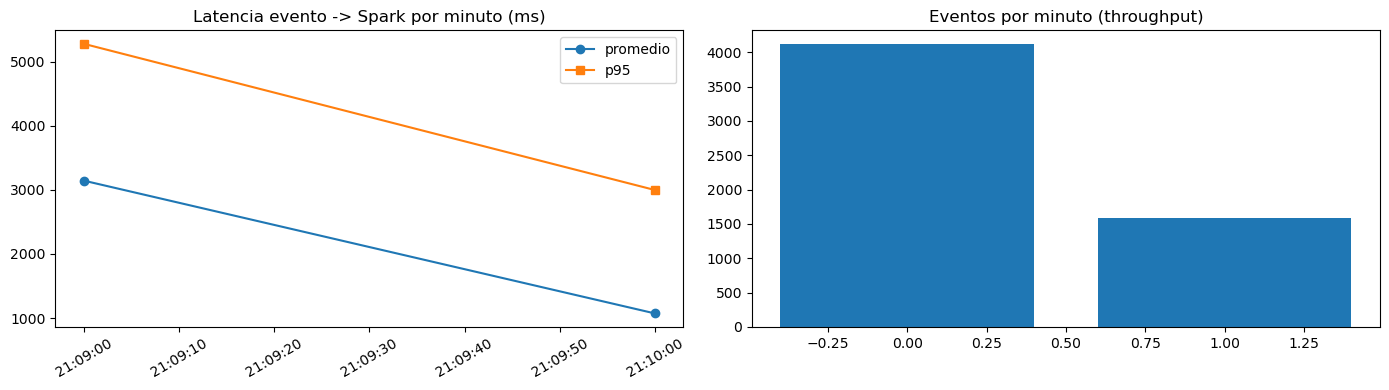

,minuto,eventos,ratio_validos,avgLatencyMs,p95LatencyMs,maxLatencyMs
0,2026-10-30 21:09:00,4113,1.0,3144.282276,5279,12736
1,2026-10-30 21:10:00,1579,1.0,1072.571248,2998,4928


In [16]:
df_obs = spark.read.parquet(RUTA_EV)
lat_min = (df_obs.groupBy(F.window("event_time", "1 minute").alias("w"))
           .agg(F.count("*").alias("eventos"), F.avg(F.col("isValid").cast("int")).alias("ratio_validos"),
                F.avg("latencyMs").alias("avgLatencyMs"), F.expr("percentile_approx(latencyMs, 0.95)").alias("p95LatencyMs"),
                F.max("latencyMs").alias("maxLatencyMs"))
           .select(F.col("w.start").alias("minuto"), "eventos", "ratio_validos", "avgLatencyMs", "p95LatencyMs", "maxLatencyMs")
           .orderBy("minuto").toPandas())
glob_lat = df_obs.filter("isValid").agg(F.avg("latencyMs").alias("avg"), F.expr("percentile_approx(latencyMs, 0.95)").alias("p95"), F.max("latencyMs").alias("max")).first()
LAT = {"avg": float(glob_lat["avg"] or 0), "p95": float(glob_lat["p95"] or 0), "max": float(glob_lat["max"] or 0)}
RESUMEN["latencia_ms"] = LAT
print(f"Latencia global (ms): promedio={LAT['avg']:.0f} | p95={LAT['p95']:.0f} | max={LAT['max']:.0f}")
if len(lat_min):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    ax[0].plot(lat_min["minuto"], lat_min["avgLatencyMs"], marker="o", label="promedio")
    ax[0].plot(lat_min["minuto"], lat_min["p95LatencyMs"], marker="s", label="p95")
    ax[0].set_title("Latencia evento -> Spark por minuto (ms)"); ax[0].legend(); ax[0].tick_params(axis="x", rotation=30)
    ax[1].bar(range(len(lat_min)), lat_min["eventos"]); ax[1].set_title("Eventos por minuto (throughput)")
    plt.tight_layout(); plt.show()
lat_min

### 3.3 Alertas con umbrales medidos

In [17]:
lag_obs = RESUMEN["progreso_spark"].get("lag_spark") or 0
umbral_lat_warn = max(2000, int(np.ceil(LAT["p95"] * 2 / 100.0) * 100))
umbral_lat_crit = umbral_lat_warn * 5
umbral_lag      = max(100, int(lag_obs * 5))
alertas = pd.DataFrame([
    {"alerta": "Broker Kafka caido", "promql": "kafka_brokers < 1", "umbral": "durante 1 min", "severidad": "critica",
     "justificacion": "sin broker no hay ingesta ni consumo"},
    {"alerta": "Retraso del consumidor", "promql": f'sum(kafka_consumergroup_lag{{consumergroup="criptoanalytics-consumer-group"}}) > {umbral_lag}',
     "umbral": "durante 2 min", "severidad": "alta", "justificacion": f"el lag medido fue {lag_obs}; 5x lo observado indica acumulacion (backpressure)"},
    {"alerta": "Latencia alta", "promql": f'cripto_spark_latencia_prom_ms{{instance="integrante{INTEGRANTE}"}} > {umbral_lat_warn}',
     "umbral": "durante 1 min", "severidad": "media", "justificacion": f"2x el p95 medido ({LAT['p95']:.0f} ms)"},
    {"alerta": "Latencia critica", "promql": f'cripto_spark_latencia_prom_ms{{instance="integrante{INTEGRANTE}"}} > {umbral_lat_crit}',
     "umbral": "durante 1 min", "severidad": "critica", "justificacion": "5x el umbral de advertencia: los datos ya no son 'tiempo real'"},
    {"alerta": "Exporter caido", "promql": 'up{job="kafka-exporter"} == 0', "umbral": "durante 1 min", "severidad": "alta",
     "justificacion": "sin exporter se pierde la observabilidad de Kafka"},
    {"alerta": "Pipeline Spark detenido", "promql": f'time() - push_time_seconds{{job="criptoanalytics_spark",instance="integrante{INTEGRANTE}"}} > 60',
     "umbral": "inmediato", "severidad": "critica", "justificacion": "Pushgateway conserva el ultimo valor: solo la antiguedad del push delata que el flujo se detuvo"},
])
RESUMEN["alertas"] = alertas.to_dict("records")
alertas

,alerta,promql,umbral,severidad,justificacion
0,Broker Kafka caido,kafka_brokers < 1,durante 1 min,critica,sin broker no hay ingesta ni consumo
1,Retraso del consumidor,"sum(kafka_consumergroup_lag{consumergroup=""cri...",durante 2 min,alta,el lag medido fue 0; 5x lo observado indica ac...
2,Latencia alta,"cripto_spark_latencia_prom_ms{instance=""integr...",durante 1 min,media,2x el p95 medido (5074 ms)
3,Latencia critica,"cripto_spark_latencia_prom_ms{instance=""integr...",durante 1 min,critica,5x el umbral de advertencia: los datos ya no s...
4,Exporter caido,"up{job=""kafka-exporter""} == 0",durante 1 min,alta,sin exporter se pierde la observabilidad de Kafka
5,Pipeline Spark detenido,"time() - push_time_seconds{job=""criptoanalytic...",inmediato,critica,Pushgateway conserva el ultimo valor: solo la ...


### 3.4 Costos y plan de escalado
Los costos de un pipeline *streaming* son distintos a los del batch de U1: el cómputo está **siempre encendido** (24×7) y el almacenamiento crece de forma continua, mientras que el batch se paga solo mientras corre.

In [18]:
# Precios de referencia (verificar vigencia antes de la sustentacion)
PRECIO_EC2_H = 0.0416     # t3.medium USD/hora
PRECIO_S3_GB = 0.023      # S3 Standard USD/GB-mes
HORAS_MES    = 730

filas_pq = RESUMEN["parquet"]["filas_corrida2"]
bytes_pq = sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(RUTA_EV) for f in fs if f.endswith(".parquet"))
bytes_fila = bytes_pq / max(filas_pq, 1)
eps = max(RESUMEN["ingesta"]["eventos_por_seg"], 0.0)

def costo(factor_volumen, instancias):
    gb_mes = eps * factor_volumen * 3600 * HORAS_MES * bytes_fila / 1e9
    return {"escenario": f"x{factor_volumen} volumen, {instancias} nodo(s)", "eventos_por_seg": round(eps * factor_volumen, 1),
            "GB_mes": round(gb_mes, 2), "USD_computo": round(instancias * PRECIO_EC2_H * HORAS_MES, 2),
            "USD_almacenamiento": round(gb_mes * PRECIO_S3_GB, 2),
            "USD_total_mes": round(instancias * PRECIO_EC2_H * HORAS_MES + gb_mes * PRECIO_S3_GB, 2)}

tabla_costos = pd.DataFrame([costo(1, 1), costo(2, 2), costo(5, 3), costo(10, 5)])
RESUMEN["costos"] = {"bytes_por_fila": round(bytes_fila, 1), "tabla": tabla_costos.to_dict("records")}
print(f"Medido: {eps:.1f} eventos/s | {bytes_fila:.0f} bytes/fila en Parquet")
print("Regla de escalado: pasar al siguiente escenario si el lag sostenido supera el umbral de alerta o la latencia promedio supera la de advertencia.")
tabla_costos

Medido: 1.2 eventos/s | 27 bytes/fila en Parquet
Regla de escalado: pasar al siguiente escenario si el lag sostenido supera el umbral de alerta o la latencia promedio supera la de advertencia.


,escenario,eventos_por_seg,GB_mes,USD_computo,USD_almacenamiento,USD_total_mes
0,"x1 volumen, 1 nodo(s)",1.2,0.09,30.37,0.00,30.37
1,"x2 volumen, 2 nodo(s)",2.4,0.17,60.74,0.00,60.74
2,"x5 volumen, 3 nodo(s)",6.0,0.43,91.10,0.01,91.11
3,"x10 volumen, 5 nodo(s)",12.0,0.86,151.84,0.02,151.86


## 4. Series de tiempo e inferencia (S10)

Los trades se agregan en **barras de `BAR_SECONDS` segundos (10 por defecto)** con la función `agregar_barras` (la misma que usará el stream). Las *features* excluyen el nivel de precio a propósito: el precio del CSV (~91–94 k) difiere del precio en vivo y un modelo que lo use se descalibra. Variable objetivo: **volumen_usdt de la barra siguiente**.

In [19]:
silver = spark.read.parquet(f"{ARTIFACTS}/silver_integrante{INTEGRANTE}").withColumn("event_time", F.col("event_timestamp"))
RUTA_BARRAS = f"{OUT}/gold_barras"
agregar_barras(silver).orderBy("bar_start").write.mode("overwrite").parquet(RUTA_BARRAS)
barras = spark.read.parquet(RUTA_BARRAS)
n_barras = barras.count()
w_ord = Window.orderBy("bar_start")
huecos = (barras.withColumn("sig", F.lead("bar_start", 1).over(w_ord))
          .filter((F.col("sig").cast("long") - F.col("bar_start").cast("long")) != BAR_SECONDS).count())
print(f"Barras historicas de {BAR_SECONDS}s: {n_barras:,} | huecos en la serie: {huecos}")
RESUMEN["barras"] = {"n": int(n_barras), "huecos": int(huecos)}
barras.orderBy("bar_start").limit(5).toPandas()

Barras historicas de 10s: 8,640 | huecos en la serie: 0


,bar_start,bar_end,n_trades,volumen_btc,volumen_usdt,qty_media,qty_max,n_ballenas,vol_ballenas_usdt,pct_buyer_maker,rango_rel,retorno
0,2026-01-05 00:00:00,2026-01-05 00:00:10,509,6.91963,633502.784558,0.013595,1.07220,2.0,152030.089122,0.033399,0.000310,0.000310
1,2026-01-05 00:00:10,2026-01-05 00:00:20,780,2.12450,194570.012594,0.002724,0.24270,0.0,0.000000,0.237179,0.000324,0.000176
2,2026-01-05 00:00:20,2026-01-05 00:00:30,311,1.37196,125650.421405,0.004411,0.13680,0.0,0.000000,0.344051,0.000133,0.000098
3,2026-01-05 00:00:30,2026-01-05 00:00:40,1077,3.33870,305668.062008,0.003100,0.22282,0.0,0.000000,0.948004,0.000747,-0.000746
4,2026-01-05 00:00:40,2026-01-05 00:00:50,493,4.12491,377528.157034,0.008367,0.50653,0.0,0.000000,0.267748,0.000277,0.000115


In [20]:
# Etiqueta = valor de TARGET_COL en la barra SIGUIENTE (solo si es contigua); division cronologica 80/20
ds = (barras.withColumn("sig_start", F.lead("bar_start", 1).over(w_ord))
      .withColumn("label_raw", F.lead(TARGET_COL, 1).over(w_ord))
      .withColumn("label", F.when((F.col("sig_start").cast("long") - F.col("bar_start").cast("long")) == BAR_SECONDS, F.col("label_raw")))
      .dropna(subset=["label"] + FEATS)
      .withColumn("pos", F.row_number().over(w_ord)))
n_ds = ds.count(); corte = int(n_ds * 0.8)
train = ds.filter(F.col("pos") <= corte).cache()
test  = ds.filter(F.col("pos") >  corte).cache()
print(f"Serie supervisada: {n_ds:,} barras | train={train.count():,} (pasado) | test={test.count():,} (futuro)")
print(f"Variable a predecir: {TARGET_COL} de la barra siguiente | features: {FEATS}")
ds.select("bar_start", TARGET_COL, "label").limit(5).toPandas()

Serie supervisada: 8,639 barras | train=6,911 (pasado) | test=1,728 (futuro)
Variable a predecir: volumen_usdt de la barra siguiente | features: ['n_trades', 'volumen_btc', 'volumen_usdt', 'qty_media', 'qty_max', 'n_ballenas', 'vol_ballenas_usdt', 'pct_buyer_maker', 'rango_rel', 'retorno']


,bar_start,volumen_usdt,label
0,2026-01-05 00:00:00,633502.784558,194570.012594
1,2026-01-05 00:00:10,194570.012594,125650.421405
2,2026-01-05 00:00:20,125650.421405,305668.062008
3,2026-01-05 00:00:30,305668.062008,377528.157034
4,2026-01-05 00:00:40,377528.157034,368112.171308


### 4.1 Baseline de persistencia y modelos
Primero se mide el baseline más simple (*la próxima barra será igual a la actual*): si un modelo no lo supera, no aporta valor.

In [21]:
def evaluar(pred):
    return {m: float(RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName=m).evaluate(pred)) for m in ["rmse", "mae", "r2"]}

# Baseline de persistencia: "la proxima barra sera igual a la actual"
res_ts = {"BASELINE_persistencia": evaluar(test.withColumn("prediction", F.col(TARGET_COL)))}

cand = {
    "LinearRegression": Pipeline(stages=[VectorAssembler(inputCols=FEATS, outputCol="f_raw"),
                                         StandardScaler(inputCol="f_raw", outputCol="features", withMean=True, withStd=True),
                                         LinearRegression(featuresCol="features", labelCol="label", regParam=0.1)]),
    "RandomForest": Pipeline(stages=[VectorAssembler(inputCols=FEATS, outputCol="features"),
                                     RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=50, maxDepth=6, seed=SEED)]),
}
modelos_ts = {}
for nombre, pipe in cand.items():
    modelos_ts[nombre] = pipe.fit(train)
    res_ts[nombre] = evaluar(modelos_ts[nombre].transform(test))

base = res_ts["BASELINE_persistencia"]
for k, v in res_ts.items():
    mejora = (base["rmse"] - v["rmse"]) / base["rmse"] * 100 if base["rmse"] else float("nan")
    v["mejora_rmse_vs_baseline_pct"] = float(mejora)
tabla_ts = pd.DataFrame(res_ts).T
tabla_ts

,rmse,mae,r2,mejora_rmse_vs_baseline_pct
BASELINE_persistencia,426281.282097,163580.394978,-0.602832,0.000000
LinearRegression,340241.086277,150614.425376,-0.021102,20.183902
RandomForest,495621.989179,182411.197364,-1.166690,-16.266421


In [22]:
mejor = min(modelos_ts, key=lambda k: res_ts[k]["rmse"])
m = res_ts[mejor]
if m["mejora_rmse_vs_baseline_pct"] > 5:
    veredicto = f"{mejor} SUPERA al baseline de persistencia por un margen relevante ({m['mejora_rmse_vs_baseline_pct']:.1f}% menos RMSE)."
elif m["mejora_rmse_vs_baseline_pct"] > 0:
    veredicto = f"{mejor} supera al baseline solo marginalmente ({m['mejora_rmse_vs_baseline_pct']:.1f}%): la complejidad adicional es dificil de justificar."
else:
    veredicto = (f"NINGUN modelo supera al baseline de persistencia (mejor: {mejor}, {m['mejora_rmse_vs_baseline_pct']:.1f}%). "
                 "Significa que la barra actual ya contiene casi toda la informacion util: es un resultado valido y se reporta asi.")
print("Mejor modelo:", mejor, "| RMSE =", round(m["rmse"], 6), "| baseline RMSE =", round(base["rmse"], 6))
print(veredicto)
RESUMEN["series_tiempo"] = {"ganador": mejor, "resultados": res_ts, "veredicto": veredicto}

Mejor modelo: LinearRegression | RMSE = 340241.086277 | baseline RMSE = 426281.282097
LinearRegression SUPERA al baseline de persistencia por un margen relevante (20.2% menos RMSE).


In [23]:
RUTA_MODELO_TS = f"{OUT}/modelo_series_tiempo"
modelos_ts[mejor].write().overwrite().save(RUTA_MODELO_TS)
cargado = PipelineModel.load(RUTA_MODELO_TS)
muestra = test.limit(200).cache(); muestra.count()
p1 = modelos_ts[mejor].transform(muestra).select("prediction").toPandas()["prediction"].to_numpy()
p2 = cargado.transform(muestra).select("prediction").toPandas()["prediction"].to_numpy()
assert np.allclose(p1, p2), "El modelo recargado no coincide"
with open(f"{OUT}/metricas_series_tiempo.json", "w") as f:
    json.dump({"target": TARGET_COL, "features": FEATS, "bar_seconds": BAR_SECONDS, "ganador": mejor, "resultados": res_ts,
               "veredicto": veredicto, "split": "cronologico_80_20"}, f, indent=2, default=str)
print(f"Modelo guardado y verificado: {RUTA_MODELO_TS}")

Modelo guardado y verificado: /home/jovyan/work/artifacts/integrante1/modelo_series_tiempo


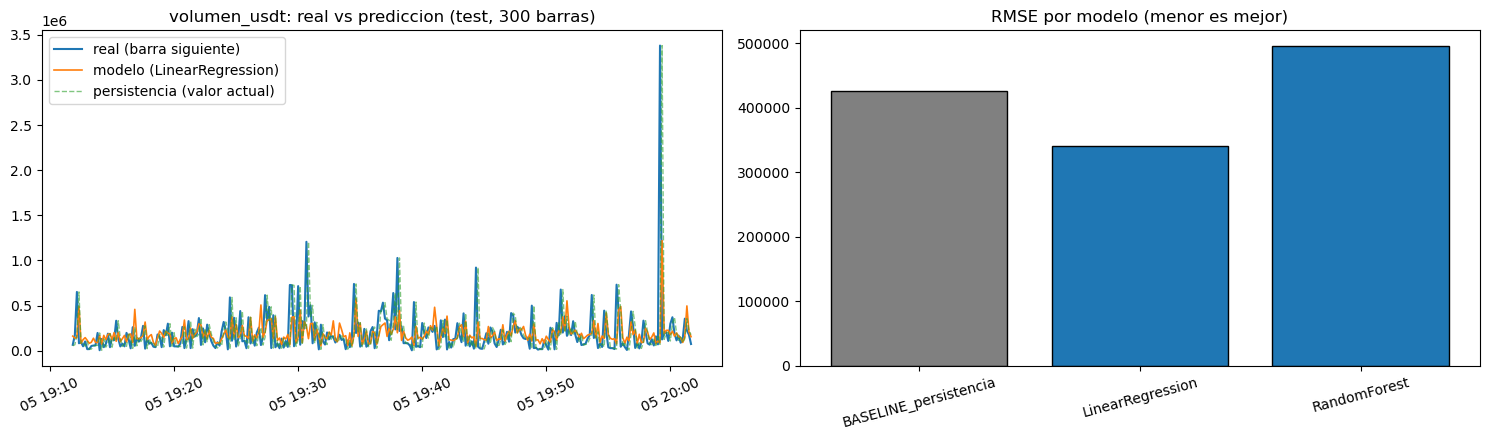

In [24]:
pdf = modelos_ts[mejor].transform(test).select("bar_start", TARGET_COL, "label", "prediction").orderBy("bar_start").limit(300).toPandas()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(pdf["bar_start"], pdf["label"], label="real (barra siguiente)", lw=1.5)
ax[0].plot(pdf["bar_start"], pdf["prediction"], label=f"modelo ({mejor})", lw=1.2)
ax[0].plot(pdf["bar_start"], pdf[TARGET_COL], label="persistencia (valor actual)", lw=1, alpha=0.6, ls="--")
ax[0].set_title(f"{TARGET_COL}: real vs prediccion (test, 300 barras)"); ax[0].legend(); ax[0].tick_params(axis="x", rotation=25)
nombres = list(res_ts); ax[1].bar(range(len(nombres)), [res_ts[n]["rmse"] for n in nombres], edgecolor="k",
                                  color=["gray" if n.startswith("BASELINE") else "tab:blue" for n in nombres])
ax[1].set_xticks(range(len(nombres))); ax[1].set_xticklabels(nombres, rotation=15); ax[1].set_title("RMSE por modelo (menor es mejor)")
plt.tight_layout(); plt.show()

## 5. BI / ML distribuido en vivo (S11)

Tres capas de métricas, que no deben confundirse: **infraestructura** (Kafka, sección 3), **aplicación** (`isValid`, `latencyMs`) y **negocio** (KPIs y predicción). Aquí se publican las de negocio.

> **Pushgateway es un atajo pragmático, no la forma recomendada:** un *job* de streaming no termina, así que no hay un endpoint estable que Prometheus pueda raspar. Lo recomendado es exponer un endpoint `/metrics` propio del proceso (cliente Prometheus); aquí se empuja a Pushgateway porque es lo más simple en un notebook.

### 5.1 KPIs de negocio (panel batch)

In [25]:
df_obs = spark.read.parquet(RUTA_EV)
base_kpi = df_obs.agg(F.count("*").alias("n"), F.avg(F.col("isValid").cast("int")).alias("ratio"), F.avg("latencyMs").alias("lat")).first()
kpis = {"cripto_kpi_eventos_total": base_kpi["n"], "cripto_kpi_ratio_validos": base_kpi["ratio"], "cripto_kpi_latencia_prom_ms": base_kpi["lat"]}
v = df_obs.filter("isValid")
a = v.agg(F.sum("quote_qty").alias("vol"), F.avg("quote_qty").alias("medio")).first()
kpis.update({"cripto_kpi_volumen_usdt_total": a["vol"], "cripto_kpi_monto_medio_usdt": a["medio"]})
ok = push("criptoanalytics_kpi", f"integrante{INTEGRANTE}", kpis, labels={"dimension": DIMENSION})
print("KPIs de negocio enviados a Pushgateway:" if ok else "KPIs calculados (Pushgateway no disponible):")
for k, val in kpis.items():
    print(f"  {k} = {val}")
RESUMEN["kpis_batch"] = {k: (float(val) if val is not None else None) for k, val in kpis.items()}

KPIs de negocio enviados a Pushgateway:
  cripto_kpi_eventos_total = 5692
  cripto_kpi_ratio_validos = 1.0
  cripto_kpi_latencia_prom_ms = 2569.5753689388616
  cripto_kpi_volumen_usdt_total = 1140671.6912933995
  cripto_kpi_monto_medio_usdt = 200.39910247600133


### 5.1b Referencia batch de U1 (panel estático, para comparar con el streaming)

In [26]:
# Referencia BATCH calculada desde el Silver de U1 (misma nomenclatura MAKER_BUY / TAKER_BUY del informe).
# Se publica como un grupo propio para poder compararla, lado a lado, con el panel en vivo.
sil = spark.read.parquet(f"{ARTIFACTS}/silver_integrante{INTEGRANTE}")
ref = (sil.groupBy("trade_type").agg(F.count("*").alias("n"), F.sum("quote_qty").alias("usdt"), F.sum("qty").alias("btc"),
                                     F.sum("es_ballena").alias("ball"), F.avg("quote_qty").alias("monto_medio"),
                                     F.avg("qty").alias("qty_media")).toPandas().set_index("trade_type"))
m, t = ref.loc["BUYER_MAKER"], ref.loc["BUYER_TAKER"]          # BUYER_MAKER = MAKER_BUY
batch = {
    "cripto_batch_share_maker_buy_ops":  m["n"] / (m["n"] + t["n"]),
    "cripto_batch_share_maker_buy_usdt": m["usdt"] / (m["usdt"] + t["usdt"]),
    "cripto_batch_volumen_usdt_maker_buy": m["usdt"], "cripto_batch_volumen_usdt_taker_buy": t["usdt"],
    "cripto_batch_monto_medio_usdt_maker_buy": m["monto_medio"], "cripto_batch_monto_medio_usdt_taker_buy": t["monto_medio"],
    "cripto_batch_qty_media_btc_maker_buy": m["qty_media"], "cripto_batch_qty_media_btc_taker_buy": t["qty_media"],
    "cripto_batch_ballenas_ratio": (m["ball"] + t["ball"]) / (m["n"] + t["n"]),
    "cripto_batch_ballenas_share_maker_buy": m["ball"] / (m["ball"] + t["ball"]) if (m["ball"] + t["ball"]) else None,
}
ok = push("criptoanalytics_batch", f"integrante{INTEGRANTE}", batch, labels={"dimension": DIMENSION})
print("Referencia batch (U1) enviada a Pushgateway:" if ok else "Referencia batch calculada (Pushgateway no disponible):")
for k, v in batch.items():
    print(f"  {k} = {v}")
RESUMEN["referencia_batch"] = {k: (float(v) if v is not None else None) for k, v in batch.items()}

Referencia batch (U1) enviada a Pushgateway:
  cripto_batch_share_maker_buy_ops = 0.4570496814413446
  cripto_batch_share_maker_buy_usdt = 0.47295339005546966
  cripto_batch_volumen_usdt_maker_buy = 911596491.6162274
  cripto_batch_volumen_usdt_taker_buy = 1015858751.9317933
  cripto_batch_monto_medio_usdt_maker_buy = 363.6000095791291
  cripto_batch_monto_medio_usdt_taker_buy = 341.08128127800825
  cripto_batch_qty_media_btc_maker_buy = 0.0039011074128272923
  cripto_batch_qty_media_btc_taker_buy = 0.003657386410230671
  cripto_batch_ballenas_ratio = 0.0005215578775201263
  cripto_batch_ballenas_share_maker_buy = 0.46627053477804964


### 5.2 Despliegue del modelo en vivo
Dos consultas *streaming* sobre el mismo flujo deduplicado: (A) barras cerradas → predicción de la barra siguiente con el modelo de serie de tiempo; (B) cada operación → modelo ganador de U1. Ambas calculan **su error contra lo que realmente ocurre** y lo publican.

In [27]:
# ---------------- Modelos desplegados ----------------
modelo_ts = PipelineModel.load(RUTA_MODELO_TS)                                          # S10: serie de tiempo (barras)
modelo_u1 = PipelineModel.load(f"{ARTIFACTS}/modelo_ganador_integrante{INTEGRANTE}")    # U1: ganador por operacion
RUTA_PRED = f"{OUT}/stream/predicciones_ts"
ROL = {1.0: "maker_buy", 0.0: "taker_buy"}     # is_buyer_maker=True -> MAKER_BUY (misma nomenclatura del informe U1)

# ---------------- (A) Serie de tiempo por barras cerradas ----------------
ESTADO_TS = {"pred_prev": None, "real_prev": None, "start_prev": None, "n": 0, "n_eval": 0,
             "abs_modelo": 0.0, "abs_persist": 0.0, "descartadas": 0, "hist": []}
FEATS_BARRA_PUSH = ["n_trades", "volumen_usdt", "qty_media", "n_ballenas", "pct_buyer_maker", "rango_rel", "retorno"]

def procesar_barras(df, batch_id):
    if df.isEmpty():
        return
    cols_pr = list(dict.fromkeys(["bar_start", TARGET_COL, "prediction"] + FEATS))   # TARGET_COL tambien es feature
    pr = modelo_ts.transform(df).select(*cols_pr).orderBy("bar_start")
    pr.write.mode("append").parquet(RUTA_PRED)
    ult = {}
    for r in pr.toPandas().to_dict("records"):
        if ESTADO_TS["descartadas"] == 0:          # la primera barra es parcial (el stream arranca a mitad de ventana)
            ESTADO_TS["descartadas"] = 1
            continue
        actual, pred, inicio = float(r[TARGET_COL]), float(r["prediction"]), r["bar_start"]
        err_m = err_p = None
        prev = ESTADO_TS["start_prev"]
        if prev is not None and (inicio - prev).total_seconds() == BAR_SECONDS:
            err_m = abs(ESTADO_TS["pred_prev"] - actual)       # lo que se predijo para esta barra
            err_p = abs(ESTADO_TS["real_prev"] - actual)       # lo que habria dicho la persistencia
            ESTADO_TS["abs_modelo"] += err_m; ESTADO_TS["abs_persist"] += err_p; ESTADO_TS["n_eval"] += 1
        ESTADO_TS.update(pred_prev=pred, real_prev=actual, start_prev=inicio, n=ESTADO_TS["n"] + 1)
        ESTADO_TS["hist"].append({"bar_start": inicio, "real": actual, "pred_siguiente": pred, "err_modelo": err_m, "err_persistencia": err_p})
        ult = {"real": actual, "pred": pred, "err": err_m, "f": r}
    if ult:
        ne = ESTADO_TS["n_eval"]
        gauges = {
            "cripto_ts_pred_proxima_barra": ult["pred"], "cripto_ts_real_ultima_barra": ult["real"],
            "cripto_ts_error_abs_ultimo": ult["err"], "cripto_ts_barras_total": ESTADO_TS["n"],
            "cripto_ts_mae_modelo": ESTADO_TS["abs_modelo"] / ne if ne else None,
            "cripto_ts_mae_persistencia": ESTADO_TS["abs_persist"] / ne if ne else None,
        }
        for k in FEATS_BARRA_PUSH:                      # estado de la ultima barra cerrada (volumen, volatilidad, rol)
            gauges[f"cripto_barra_{k}"] = float(ult["f"][k])
        push("criptoanalytics_ts", f"integrante{INTEGRANTE}", gauges, labels={"dimension": DIMENSION})

# ---------------- (B) Modelo U1 por operacion: metricas propias de la dimension ----------------
ESTADO_U1 = {"n": 0, "abs": 0.0, "sq": 0.0, "sy": 0.0, "sy2": 0.0,
             "abs_r": {"maker_buy": 0.0, "taker_buy": 0.0}, "n_r": {"maker_buy": 0, "taker_buy": 0}}
def metricas_u1(pred):
    y = F.col("quote_qty"); err = y - F.col("prediction")
    filas = pred.groupBy("is_buyer_maker_num").agg(
        F.count("*").alias("n"), F.sum(F.abs(err)).alias("abs"), F.sum(err ** 2).alias("sq"),
        F.sum(y).alias("sy"), F.sum(y ** 2).alias("sy2")).collect()
    e = ESTADO_U1; n_lote, abs_lote = 0, 0.0
    for r in filas:
        rol = ROL[r["is_buyer_maker_num"]]
        e["n"] += r["n"]; e["abs"] += r["abs"] or 0.0; e["sq"] += r["sq"] or 0.0
        e["sy"] += r["sy"] or 0.0; e["sy2"] += r["sy2"] or 0.0
        e["abs_r"][rol] += r["abs"] or 0.0; e["n_r"][rol] += r["n"]
        n_lote += r["n"]; abs_lote += r["abs"] or 0.0
    ult = pred.orderBy(F.col("event_ts_ms").desc(), F.col("trade_id").desc()).select("quote_qty", "prediction").first()
    sst = e["sy2"] - e["sy"] ** 2 / e["n"]
    g = {"cripto_u1_trades_evaluados_total": e["n"], "cripto_u1_mae_acum": e["abs"] / e["n"],
         "cripto_u1_rmse_acum": (e["sq"] / e["n"]) ** 0.5, "cripto_u1_mae_lote": abs_lote / n_lote,
         "cripto_u1_r2_acum": (1 - e["sq"] / sst) if sst > 0 else None,
         "cripto_u1_ultimo_real": ult[0], "cripto_u1_ultimo_pred": ult[1]}
    for rol in ("maker_buy", "taker_buy"):
        if e["n_r"][rol]:
            g[f"cripto_u1_mae_{rol}"] = e["abs_r"][rol] / e["n_r"][rol]
    return g

# ---------------- (C) Comportamiento del volumen por rol + observabilidad de Spark (comun a las 4 dimensiones) ----------------
ESTADO_LIVE = {"n": {"maker_buy": 0, "taker_buy": 0}, "usdt": {"maker_buy": 0.0, "taker_buy": 0.0},
               "btc": {"maker_buy": 0.0, "taker_buy": 0.0}, "ball": {"maker_buy": 0.0, "taker_buy": 0.0}}

def procesar_u1(df, batch_id):
    if df.isEmpty():
        return
    ag = (df.groupBy("is_buyer_maker_num")
          .agg(F.count("*").alias("n"), F.sum("quote_qty").alias("usdt"), F.sum("qty").alias("btc"),
               F.sum("es_ballena").alias("ball"), F.sum("latencyMs").alias("lat_sum"), F.max("latencyMs").alias("lat_max"),
               F.min("price").alias("pmin"), F.max("price").alias("pmax"), F.avg("price").alias("pavg")).collect())
    L = ESTADO_LIVE
    n_lote, lat_sum, lat_max, pmin, pmax, psum = 0, 0.0, 0.0, float("inf"), 0.0, 0.0
    for r in ag:
        rol = ROL[r["is_buyer_maker_num"]]
        L["n"][rol] += r["n"]; L["usdt"][rol] += r["usdt"] or 0.0; L["btc"][rol] += r["btc"] or 0.0; L["ball"][rol] += r["ball"] or 0.0
        n_lote += r["n"]; lat_sum += r["lat_sum"] or 0.0; lat_max = max(lat_max, r["lat_max"] or 0.0)
        pmin = min(pmin, r["pmin"]); pmax = max(pmax, r["pmax"]); psum += r["pavg"] * r["n"]
    live = {}
    for rol in ("maker_buy", "taker_buy"):
        live[f"cripto_live_trades_total_{rol}"] = L["n"][rol]
        live[f"cripto_live_volumen_usdt_total_{rol}"] = L["usdt"][rol]
        live[f"cripto_live_volumen_btc_total_{rol}"] = L["btc"][rol]
        live[f"cripto_live_ballenas_total_{rol}"] = L["ball"][rol]
        if L["n"][rol]:
            live[f"cripto_live_monto_medio_usdt_{rol}"] = L["usdt"][rol] / L["n"][rol]
            live[f"cripto_live_qty_media_btc_{rol}"] = L["btc"][rol] / L["n"][rol]
    tn, tu = sum(L["n"].values()), sum(L["usdt"].values())
    live["cripto_live_share_maker_buy_ops"] = L["n"]["maker_buy"] / tn
    live["cripto_live_share_maker_buy_usdt"] = L["usdt"]["maker_buy"] / tu if tu else None
    live["cripto_live_ballenas_ratio"] = sum(L["ball"].values()) / tn
    live["cripto_live_fluctuacion_rel_lote"] = (pmax - pmin) / (psum / n_lote)
    push("criptoanalytics_live", f"integrante{INTEGRANTE}", live, labels={"dimension": DIMENSION})
    push("criptoanalytics_spark", f"integrante{INTEGRANTE}", {
        "cripto_spark_latencia_prom_ms": lat_sum / n_lote, "cripto_spark_latencia_max_ms": lat_max,
        "cripto_spark_filas_lote": n_lote, "cripto_spark_lote_id": batch_id}, labels={"dimension": DIMENSION})
    push("criptoanalytics_u1", f"integrante{INTEGRANTE}", metricas_u1(modelo_u1.transform(df)), labels={"dimension": DIMENSION})
print("Funciones de despliegue definidas.")

Funciones de despliegue definidas.


In [28]:
ev_live = (ev_stream().filter("isValid").withWatermark("event_time", WATERMARK).dropDuplicates(["trade_id", "event_time"]))

q_barras = (agregar_barras(ev_live).writeStream.outputMode("append").queryName("live_barras")
            .foreachBatch(procesar_barras).option("checkpointLocation", f"{CKPT}/live_barras_{RUN_ID}")
            .trigger(processingTime="5 seconds").start())
q_u1 = (ev_live.writeStream.outputMode("append").queryName("live_u1")
        .foreachBatch(procesar_u1).option("checkpointLocation", f"{CKPT}/live_u1_{RUN_ID}")
        .trigger(processingTime="5 seconds").start())

t_fin = time.time() + LIVE_SECONDS * WAIT_SCALE
while time.time() < t_fin:
    time.sleep(min(30 * WAIT_SCALE, max(t_fin - time.time(), 0.1)))
    e = ESTADO_TS; ne = e["n_eval"]
    print(f"[{datetime.now().strftime('%H:%M:%S')}] barras={e['n']} evaluadas={ne} | "
          f"MAE modelo={e['abs_modelo']/ne if ne else float('nan'):.4f} vs persistencia={e['abs_persist']/ne if ne else float('nan'):.4f} | "
          f"U1 trades evaluados={ESTADO_U1['n']:,}")

[21:10:57] barras=1 evaluadas=0 | MAE modelo=nan vs persistencia=nan | U1 trades evaluados=1,483
[21:11:27] barras=4 evaluadas=3 | MAE modelo=226471.7485 vs persistencia=59042.4798 | U1 trades evaluados=3,955
[21:11:57] barras=7 evaluadas=6 | MAE modelo=317622.1963 vs persistencia=101595.0327 | U1 trades evaluados=5,071
[21:12:27] barras=10 evaluadas=9 | MAE modelo=278308.0403 vs persistencia=82361.9695 | U1 trades evaluados=6,032
[21:12:57] barras=13 evaluadas=12 | MAE modelo=269190.1959 vs persistencia=69779.9194 | U1 trades evaluados=6,642


### 5.3 Confirmar que es en vivo (dos consultas PromQL separadas en el tiempo)

In [29]:
inst = f"integrante{INTEGRANTE}"
def leer(metrica):
    r = promql(f'{metrica}{{instance="{inst}"}}')
    return float(r[0]["value"][1]) if r else None

q1 = {m: leer(m) for m in ["cripto_ts_barras_total", "cripto_u1_trades_evaluados_total"]}
print("Consulta 1:", q1)
esperar(30, "esperando (Prometheus raspa el Pushgateway cada 15 s)")
q2 = {m: leer(m) for m in ["cripto_ts_barras_total", "cripto_u1_trades_evaluados_total"]}
print("Consulta 2:", q2)
cambio = all(q1[m] is not None and q2[m] is not None and q2[m] != q1[m] for m in q1)
print("RESULTADO:", "los valores cambian entre consultas: el dato es EN VIVO" if cambio else "sin cambio o Prometheus no disponible: revisar")
RESUMEN["promql_en_vivo"] = {"consulta1": q1, "consulta2": q2, "cambia": bool(cambio)}

Consulta 1: {'cripto_ts_barras_total': 12.0, 'cripto_u1_trades_evaluados_total': 6578.0}
... esperando (Prometheus raspa el Pushgateway cada 15 s) (30s)
Consulta 2: {'cripto_ts_barras_total': 15.0, 'cripto_u1_trades_evaluados_total': 7537.0}
RESULTADO: los valores cambian entre consultas: el dato es EN VIVO


### 5.4 Detener y revisar el comportamiento en vivo

{'barras': 159, 'evaluadas': 158, 'mae_modelo': 226041.44628690835, 'mae_persistencia': 61868.31599632345, 'u1_trades_evaluados': 47562}


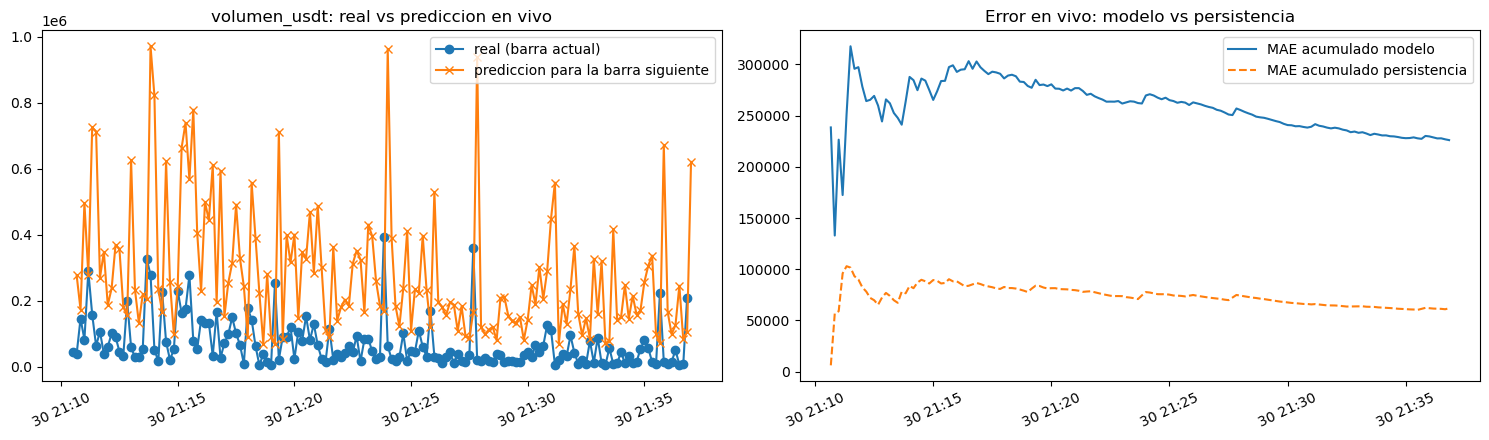

,bar_start,real,pred_siguiente,err_modelo,err_persistencia
151,2026-10-30 21:35:40,223763.746613,671730.721894,152235.249913,215960.629262
152,2026-10-30 21:35:50,15235.769593,166168.859818,656494.952301,208527.977020
153,2026-10-30 21:36:00,7792.987630,99135.257052,158375.872188,7442.781963
154,2026-10-30 21:36:10,14660.563015,126273.132166,84474.694036,6867.575386
155,2026-10-30 21:36:20,51167.468439,245716.911691,75105.663727,36506.905424
156,2026-10-30 21:36:30,6251.145224,83451.925105,239465.766467,44916.323215
157,2026-10-30 21:36:40,7116.605529,106799.138574,76335.319576,865.460305
158,2026-10-30 21:36:50,209954.553743,620881.521306,103155.415169,202837.948214


In [30]:
for q in (q_barras, q_u1):
    q.stop()
ne = ESTADO_TS["n_eval"]
live = {"barras": ESTADO_TS["n"], "evaluadas": ne,
        "mae_modelo": ESTADO_TS["abs_modelo"] / ne if ne else None,
        "mae_persistencia": ESTADO_TS["abs_persist"] / ne if ne else None,
        "u1_trades_evaluados": ESTADO_U1["n"]}
RESUMEN["live"] = live
print(live)
hist = pd.DataFrame(ESTADO_TS["hist"])
if len(hist):
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
    ax[0].plot(hist["bar_start"], hist["real"], marker="o", label="real (barra actual)")
    ax[0].plot(hist["bar_start"] + pd.Timedelta(seconds=BAR_SECONDS), hist["pred_siguiente"], marker="x", label="prediccion para la barra siguiente")
    ax[0].set_title(f"{TARGET_COL}: real vs prediccion en vivo"); ax[0].legend(); ax[0].tick_params(axis="x", rotation=25)
    h = hist.dropna(subset=["err_modelo"])
    if len(h):
        ax[1].plot(h["bar_start"], h["err_modelo"].expanding().mean(), label="MAE acumulado modelo")
        ax[1].plot(h["bar_start"], h["err_persistencia"].expanding().mean(), label="MAE acumulado persistencia", ls="--")
        ax[1].set_title("Error en vivo: modelo vs persistencia"); ax[1].legend(); ax[1].tick_params(axis="x", rotation=25)
    plt.tight_layout(); plt.show()
hist.tail(8)

### 5.5 Tablero BI en Grafana (panel batch + panel en vivo, lado a lado)

Importa `dashboard_criptoanalytics_u2.json` (Grafana → Dashboards → New → Import). El tablero responde, sobre la **capa streaming**, las mismas preguntas de negocio de U1:

| Pregunta | Dónde se responde |
|---|---|
| Pregunta central: ¿cómo se comporta el volumen y qué tan predecible es el monto? | Fila "Pregunta central": volumen por rol en vivo, % maker_buy batch vs streaming, error del modelo |
| Pregunta de mi dimensión (`monto_usdt`) | Fila "Integrante 1": métricas `cripto_u1_*`, `cripto_ts_*` y `cripto_barra_*` con `instance="integrante1"` |
| ¿El pipeline está sano? | Eventos/s, latencia de Spark y brokers |

La predicción **junto** a los KPIs en el mismo tablero permite ver si el modelo sigue la realidad del negocio y detectar cuándo se descalibra.

## 6. Cierre: criterios de aceptación de S12

In [31]:
detener = [q.name for q in spark.streams.active]
for q in spark.streams.active:
    q.stop()
R = RESUMEN
checks = {
    "Evento de negocio publicado y consumido en vivo por Kafka": R.get("ingesta", {}).get("eventos_por_seg", 0) > 0 and bool(R.get("validacion")),
    "Ventana + watermark verificados (tardio descartado)": R.get("tardio", {}).get("descartado") is True,
    "Deduplicacion verificada": R.get("dedup", {}).get("salida") == 2,
    "Checkpoint: la corrida 2 acumula sobre la 1": R.get("parquet", {}).get("filas_corrida2", 0) > R.get("parquet", {}).get("filas_corrida1", 0),
    "Observabilidad: latencia medida y alertas con umbrales": bool(R.get("latencia_ms")) and bool(R.get("alertas")),
    "Costos de escalado estimados": bool(R.get("costos")),
    "Serie de tiempo validada contra baseline de persistencia": bool(R.get("series_tiempo")),
    "KPIs de negocio enviados a Pushgateway": bool(R.get("kpis_batch")),
    "Inferencia en vivo (serie + modelo U1) con error medido": R.get("live", {}).get("evaluadas", 0) > 0,
    "PromQL confirma datos en vivo": R.get("promql_en_vivo", {}).get("cambia") is True,
}
for k, v in checks.items():
    print(("[OK] " if v else "[ ] ") + k)
RESUMEN["checklist_s12"] = checks
with open(f"{OUT}/resumen_u2.json", "w") as f:
    json.dump(RESUMEN, f, indent=2, default=str)
print(f"\nResumen guardado en {OUT}/resumen_u2.json")
print("Artefactos de este integrante:")
for p in sorted(os.listdir(OUT)):
    print("  ", p)

[OK] Evento de negocio publicado y consumido en vivo por Kafka
[OK] Ventana + watermark verificados (tardio descartado)
[OK] Deduplicacion verificada
[OK] Checkpoint: la corrida 2 acumula sobre la 1
[OK] Observabilidad: latencia medida y alertas con umbrales
[OK] Costos de escalado estimados
[OK] Serie de tiempo validada contra baseline de persistencia
[OK] KPIs de negocio enviados a Pushgateway
[OK] Inferencia en vivo (serie + modelo U1) con error medido
[OK] PromQL confirma datos en vivo

Resumen guardado en /home/jovyan/work/artifacts/integrante1/resumen_u2.json
Artefactos de este integrante:
   checkpoints
   gold_barras
   metricas_series_tiempo.json
   modelo_series_tiempo
   resumen_u2.json
   stream


### Para la sustentación (3 min de demo + 3 min de preguntas)
1. Cómo evolucionó el pipeline de U1 (batch) a U2 (streaming): mismas dimensiones, nueva fuente y nuevo modo de cálculo.
2. Evento publicado y consumido en vivo; validación de esquema y de rango.
3. Ventana + *watermark* + *checkpoint* verificados en la salida de este notebook.
4. Panel de observabilidad y costos de escalado.
5. Serie de tiempo contra el baseline de persistencia y su veredicto (aunque no gane).
6. Tablero con KPIs y predicción en vivo.
7. **Una decisión propia** distinta al ejemplo del docente (por ejemplo: excluir el nivel de precio de las *features*, o la dimensión elegida y su variable objetivo).